<a href="https://colab.research.google.com/github/attaboatengsr/data620/blob/main/data620_week6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install igraph -q
%pip install pandas -q
%pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 20.4 MB/s eta 0:00:00


In [2]:
import igraph as ig
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

Biadjacency matrix
<Compressed Sparse Row sparse array of dtype 'int64'
	with 89 stored elements and shape (18, 14)>
  Coords	Values
  (0, 0)	1
  (0, 1)	1
  (0, 2)	1
  (0, 3)	1
  (0, 4)	1
  (0, 5)	1
  (0, 7)	1
  (0, 8)	1
  (1, 0)	1
  (1, 1)	1
  (1, 2)	1
  (1, 4)	1
  (1, 5)	1
  (1, 6)	1
  (1, 7)	1
  (2, 1)	1
  (2, 2)	1
  (2, 3)	1
  (2, 4)	1
  (2, 5)	1
  (2, 6)	1
  (2, 7)	1
  (2, 8)	1
  (3, 0)	1
  (3, 2)	1
  :	:
  (12, 7)	1
  (12, 8)	1
  (12, 9)	1
  (12, 11)	1
  (12, 12)	1
  (12, 13)	1
  (13, 5)	1
  (13, 6)	1
  (13, 8)	1
  (13, 9)	1
  (13, 10)	1
  (13, 11)	1
  (13, 12)	1
  (13, 13)	1
  (14, 6)	1
  (14, 7)	1
  (14, 9)	1
  (14, 10)	1
  (14, 11)	1
  (15, 7)	1
  (15, 8)	1
  (16, 8)	1
  (16, 10)	1
  (17, 8)	1
  (17, 10)	1

#Friends, Member
17 Evelyn Jefferson
15 Laura Mandeville
17 Theresa Anderson
15 Brenda Rogers
11 Charlotte McDowd
15 Frances Anderson
15 Eleanor Nye
16 Pearl Oglethorpe
17 Ruth DeSand
17 Verne Sanderson
16 Myra Liddel
16 Katherina Rogers
17 Sylvia Avondale
17 Nora Fayette
1

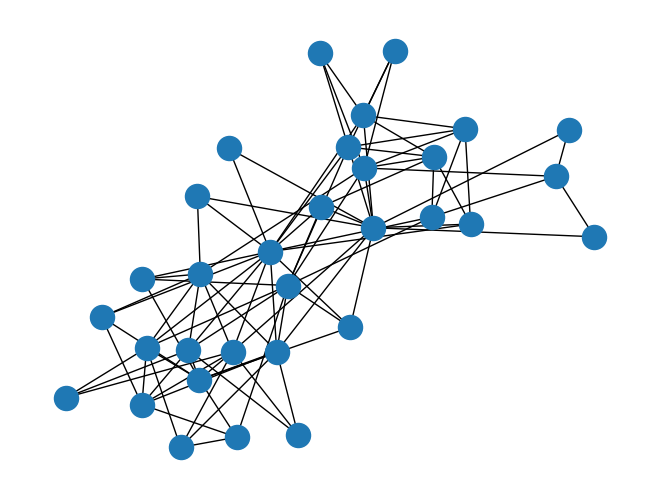

In [7]:
##This section was take from
##https://networkx.org/documentation/stable/auto_examples/algorithms/plot_davis_club.html
##to get the dataset.

G = nx.davis_southern_women_graph()
women = G.graph["top"]
clubs = G.graph["bottom"]

print("Biadjacency matrix")
print(bipartite.biadjacency_matrix(G, women, clubs))

# project bipartite graph onto women nodes
W = bipartite.projected_graph(G, women)
print()
print("#Friends, Member")
for w in women:
    print(f"{W.degree(w)} {w}")

# project bipartite graph onto women nodes keeping number of co-occurrence
# the degree computed is weighted and counts the total number of shared contacts
W = bipartite.weighted_projected_graph(G, women)
print()
print("#Friend meetings, Member")
for w in women:
    print(f"{W.degree(w, weight='weight')} {w}")

pos = nx.spring_layout(G, seed=648)  # Seed layout for reproducible node positions
nx.draw(G, pos)
plt.show()

In [9]:

# Calculate degree centrality for the bipartite graph G
# This gives centrality values normalized by the maximum possible degree in a bipartite graph
deg_centrality = bipartite.degree_centrality(G, women)

# Filter the results to only include the women nodes
women_centrality = {node: deg_centrality[node] for node in women}

# Create a pandas DataFrame to display the results
df_centrality = pd.DataFrame(list(women_centrality.items()), columns=['Woman', 'Degree Centrality'])
df_centrality = df_centrality.sort_values(by='Degree Centrality', ascending=False).reset_index(drop=True)

display(df_centrality.sort_values(by='Degree Centrality', ascending=False).head(10))

,Woman,Degree Centrality
0,Evelyn Jefferson,0.571429
1,Theresa Anderson,0.571429
2,Nora Fayette,0.571429
3,Laura Mandeville,0.500000
4,Sylvia Avondale,0.500000
5,Brenda Rogers,0.500000
6,Katherina Rogers,0.428571
7,Helen Lloyd,0.357143
8,Charlotte McDowd,0.285714
9,Frances Anderson,0.285714


Evelyn Jefferson, Theresa Anderson, and Nora Fayette seen to have the highest degree centrality. They seem to be the anchors of the community even though they are different groups.